# Kv2.1 50% masked S6-shift comparison

    This is the canonical comparison for the current release. It uses only the corrected masked_v3_50pct cohorts and convergence-qualified all_ok_3 tables for WT, L403A, and F412L. No vanilla cohort, legacy date, or prior release is loaded.

    The primary question is whether the L403A S6 displacement is reproduced in the current 50% ensemble, with F412L retained as a mutation-specific comparison.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "shared").is_dir())
sys.path.insert(0, str(ROOT))
from shared.dataset_selection import (
    distance_csv_options, kv21_active_masked_distance_path,
    load_selected_distance_csv,
)

CONDITIONS = ("WT", "L403A", "F412L")
PROTOCOL = "masked_v3_50pct"
SELECTION = "all_ok_3"

def load_condition(condition):
    original = kv21_active_masked_distance_path(ROOT, condition)
    options = distance_csv_options(ROOT, original, "kv21", condition, PROTOCOL)
    source = str(options[SELECTION])
    assert "50pct" in source and "vanilla" not in source.lower(), source
    frame = load_selected_distance_csv(
        f"Kv2.1 {condition} | 50% masked", options, SELECTION,
        fallback_to_all=False,
    ).copy()
    assert frame.attrs["actual_selection"] == SELECTION
    frame["Condition"] = condition
    frame["Protocol"] = PROTOCOL
    return frame, source

datasets, source_paths = {}, {}
for condition in CONDITIONS:
    datasets[condition], source_paths[condition] = load_condition(condition)
assert all("50pct" in p and "vanilla" not in p.lower() for p in source_paths.values())
for condition, path in source_paths.items():
    print(f"{condition}: {path} | n={len(datasets[condition]):,}")

Merged companion distance table: kv21/dataDistances/26-11-12_Kv2.1_wt_masked_v3_50pct_AF2_distances_extra_all_ok_rmsd_3A.csv
Kv2.1 WT | 50% masked: requested=all_ok_3; actual=all_ok_3; path=kv21/dataDistances/26-11-12_Kv2.1_wt_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv


Merged companion distance table: kv21/dataDistances/26-11-12_Kv2.1_l403a_masked_v3_50pct_AF2_distances_extra_all_ok_rmsd_3A.csv
Kv2.1 L403A | 50% masked: requested=all_ok_3; actual=all_ok_3; path=kv21/dataDistances/26-11-12_Kv2.1_l403a_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv


Merged companion distance table: kv21/dataDistances/26-11-12_Kv2.1_f412l_masked_v3_50pct_AF2_distances_extra_all_ok_rmsd_3A.csv
Kv2.1 F412L | 50% masked: requested=all_ok_3; actual=all_ok_3; path=kv21/dataDistances/26-11-12_Kv2.1_f412l_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv
WT: kv21/dataDistances/26-11-12_Kv2.1_wt_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv | n=4,493
L403A: kv21/dataDistances/26-11-12_Kv2.1_l403a_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv | n=4,647
F412L: kv21/dataDistances/26-11-12_Kv2.1_f412l_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv | n=3,924


In [2]:
DISTANCE_COLUMNS = [f"CA_CA_{chain}_GLU425_CA-{chain}_ASN181_CA" for chain in "ABCD"]
assert not any(
    [column for column in DISTANCE_COLUMNS if column not in frame.columns]
    for frame in datasets.values()
)
SHIFT_THRESHOLD_A = 12.841337

def metrics(frame):
    result = frame[["pdb_file", "Condition", "Protocol", *DISTANCE_COLUMNS]].copy()
    result[DISTANCE_COLUMNS] = result[DISTANCE_COLUMNS].apply(pd.to_numeric, errors="coerce")
    result = result.dropna(subset=DISTANCE_COLUMNS).copy()
    result["max_S6_span_A"] = result[DISTANCE_COLUMNS].max(axis=1)
    result["median_S6_span_A"] = result[DISTANCE_COLUMNS].median(axis=1)
    result["shifted_subunits"] = (result[DISTANCE_COLUMNS] >= SHIFT_THRESHOLD_A).sum(axis=1)
    result["any_shifted"] = result["shifted_subunits"].ge(1)
    result["exactly_two_shifted"] = result["shifted_subunits"].eq(2)
    result["all_four_shifted"] = result["shifted_subunits"].eq(4)
    parsed = result["pdb_file"].str.extract(r"seed_(?P<seed>\d+).*?\.r(?P<recycle>\d+)\.pdb$")
    result["seed"] = pd.to_numeric(parsed["seed"], errors="coerce")
    result["recycle"] = pd.to_numeric(parsed["recycle"], errors="coerce")
    return result

long = pd.concat([metrics(frame) for frame in datasets.values()], ignore_index=True)
summary = (
    long.groupby("Condition", sort=False)
    .agg(
        n_models=("pdb_file", "size"), n_seeds=("seed", "nunique"),
        median_max_S6_span_A=("max_S6_span_A", "median"),
        q025_max_S6_span_A=("max_S6_span_A", lambda x: x.quantile(0.025)),
        q975_max_S6_span_A=("max_S6_span_A", lambda x: x.quantile(0.975)),
        fraction_any_shifted=("any_shifted", "mean"),
        fraction_exactly_two=("exactly_two_shifted", "mean"),
        fraction_all_four=("all_four_shifted", "mean"),
    ).reset_index()
)
summary

,Condition,n_models,n_seeds,median_max_S6_span_A,q025_max_S6_span_A,q975_max_S6_span_A,fraction_any_shifted,fraction_exactly_two,fraction_all_four
0,WT,4493,100,10.90,9.88,44.13400,0.028711,0.004451,0.024037
1,L403A,4647,100,10.85,9.96,12.10000,0.010975,0.000215,0.010329
2,F412L,3924,100,12.87,11.10,44.00625,0.515545,0.030836,0.435015


In [3]:
rng = np.random.default_rng(20261113)

def bootstrap_difference(left, right, column, n_boot=5000):
    left = pd.to_numeric(left[column], errors="coerce").dropna().to_numpy(float)
    right = pd.to_numeric(right[column], errors="coerce").dropna().to_numpy(float)
    observed = np.median(left) - np.median(right)
    draws = np.empty(n_boot)
    for i in range(n_boot):
        draws[i] = (
            np.median(rng.choice(left, len(left), replace=True))
            - np.median(rng.choice(right, len(right), replace=True))
        )
    return observed, np.quantile(draws, [0.025, 0.975])

rows = []
for mutant in ("L403A", "F412L"):
    for metric in ("max_S6_span_A", "median_S6_span_A", "shifted_subunits"):
        observed, interval = bootstrap_difference(
            long[long.Condition == mutant], long[long.Condition == "WT"], metric
        )
        rows.append({
            "contrast": f"{mutant} - WT", "metric": metric,
            "difference_median": observed, "ci95_low": interval[0],
            "ci95_high": interval[1],
        })
contrast_table = pd.DataFrame(rows)
contrast_table

,contrast,metric,difference_median,ci95_low,ci95_high
0,L403A - WT,max_S6_span_A,-0.050,-0.080,-0.03
1,L403A - WT,median_S6_span_A,-0.055,-0.085,-0.03
2,L403A - WT,shifted_subunits,0.000,0.000,0.00
3,F412L - WT,max_S6_span_A,1.970,1.940,2.01
4,F412L - WT,median_S6_span_A,1.930,1.890,1.97
5,F412L - WT,shifted_subunits,1.000,1.000,2.00


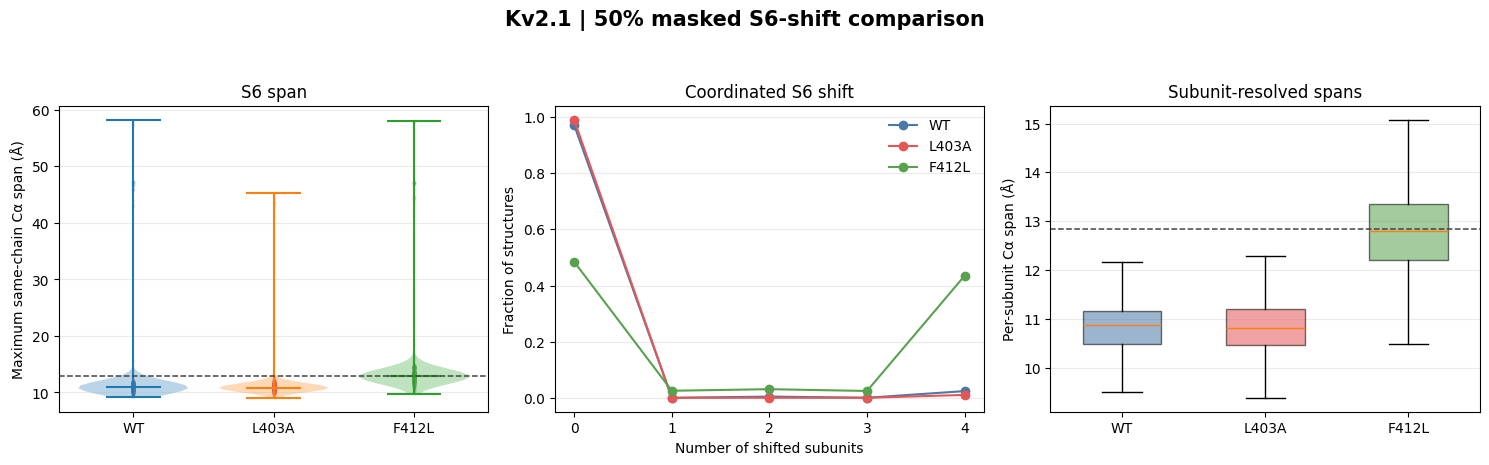

Wrote <repository-root>/docs/figures/kv21_50pct_s6_shift/kv21_50pct_s6_shift_comparison.png


In [4]:
out_fig = ROOT / "docs" / "figures" / "kv21_50pct_s6_shift"
out_tab = ROOT / "docs" / "tables" / "kv21_50pct_s6_shift"
out_fig.mkdir(parents=True, exist_ok=True)
out_tab.mkdir(parents=True, exist_ok=True)
palette = {"WT": "#4C78A8", "L403A": "#E45756", "F412L": "#59A14F"}
order = list(CONDITIONS)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.7))
for i, condition in enumerate(order):
    values = long.loc[long.Condition == condition, "max_S6_span_A"]
    sample = values.sample(min(700, len(values)), random_state=7)
    axes[0].violinplot(values, positions=[i], showmedians=True, widths=0.78)
    axes[0].scatter(np.full(len(sample), i), sample, s=3, alpha=0.08, color=palette[condition])
axes[0].axhline(SHIFT_THRESHOLD_A, color="#444444", linestyle="--", linewidth=1.1)
axes[0].set_xticks(range(len(order)), order)
axes[0].set_ylabel("Maximum same-chain Cα span (Å)")
axes[0].set_title("S6 span")
axes[0].grid(axis="y", alpha=0.25)

for condition in order:
    values = long.loc[long.Condition == condition, "shifted_subunits"]
    counts = values.value_counts().reindex(range(5), fill_value=0) / len(values)
    axes[1].plot(range(5), counts.values, marker="o", color=palette[condition], label=condition)
axes[1].set_xticks(range(5), ["0", "1", "2", "3", "4"])
axes[1].set_xlabel("Number of shifted subunits")
axes[1].set_ylabel("Fraction of structures")
axes[1].set_title("Coordinated S6 shift")
axes[1].legend(frameon=False)
axes[1].grid(axis="y", alpha=0.25)

for i, condition in enumerate(order):
    values = long.loc[long.Condition == condition, DISTANCE_COLUMNS].to_numpy(float).ravel()
    axes[2].boxplot(values, positions=[i], widths=0.55, showfliers=False,
                    patch_artist=True,
                    boxprops={"facecolor": palette[condition], "alpha": 0.55})
axes[2].axhline(SHIFT_THRESHOLD_A, color="#444444", linestyle="--", linewidth=1.1)
axes[2].set_xticks(range(len(order)), order)
axes[2].set_ylabel("Per-subunit Cα span (Å)")
axes[2].set_title("Subunit-resolved spans")
axes[2].grid(axis="y", alpha=0.25)
fig.suptitle("Kv2.1 | 50% masked S6-shift comparison", fontsize=15, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(out_fig / "kv21_50pct_s6_shift_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

summary.to_csv(out_tab / "cohort_summary.csv", index=False)
contrast_table.to_csv(out_tab / "bootstrap_contrasts.csv", index=False)
long.to_csv(out_tab / "per_structure_s6_shift_metrics.csv", index=False)
pd.DataFrame({
    "condition": list(source_paths), "source_path": list(source_paths.values()),
    "protocol": PROTOCOL, "selection": SELECTION,
}).to_csv(out_tab / "source_manifest.csv", index=False)
print(f"Wrote {out_fig / 'kv21_50pct_s6_shift_comparison.png'}")

## Interpretation boundary

    The thresholded counts describe the same-chain S6-span signature used for the Kv2.1 comparison. They do not by themselves establish a full coordinated pore rotation; the per-subunit distributions and the structural reference analysis should be considered together.